# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en la página de inicio (landing page) de un ecommerce, con dos versiones (**A** = control y **B** = prueba), para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de 40,000 usuarios expuestos a una de las dos versiones de la página. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.
2. 💰 Comparar el **gasto promedio** por usuario convertido entre la página A y B (prueba t).
3. 🎯 Comparar la **tasa de conversión** entre la página A y B (prueba z de proporciones).
4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión** (chi-cuadrada).
5. 👤 Revisar **la relación entre el tipo de usuario y la conversión** (chi-cuadrada).
6. 📈 **Visualizar los resultados** para respaldar las conclusiones.
7. 🧩 Traducir los hallazgos en un **insight ejecutivo** con recomendaciones.

Todas las pruebas usan un nivel de significancia **α = 0.05**.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, levene, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest
from itertools import combinations

# nivel de significancia para todas las pruebas
alpha = 0.05

In [2]:
# cargar archivo
df = pd.read_csv('landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

# valores nulos y filas duplicadas
print("\nValores nulos por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  str    
 1   date            40000 non-null  str    
 2   landing         40000 non-null  str    
 3   region          40000 non-null  str    
 4   dispositivo     40000 non-null  str    
 5   traffic_source  40000 non-null  str    
 6   user_type       40000 non-null  str    
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), str(7)
memory usage: 2.7 MB

Valores nulos por columna:
user_id           0
date              0
landing           0
region            0
dispositivo       0
traffic_source    0
user_type         0
converted         0
gasto             0
dtype: int64

Filas duplicadas: 0


📌 **Hallazgos**

- El dataset tiene **40,000 filas y 9 columnas**.
- **No hay valores nulos** en ninguna columna ni filas duplicadas.
- La columna `date` está almacenada como texto y se convierte a `datetime` con `pd.to_datetime()` en la revisión de fechas.
- `converted` es entero (0/1) y `gasto` es `float`, que son los tipos correctos.
- `user_id` es un **identificador único**; `landing`, `region`, `dispositivo`, `traffic_source` y `user_type` son variables **categóricas**.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
# Verificar usuarios únicos
print("Total de filas:", len(df))
print("Usuarios únicos:", df["user_id"].nunique())
print("user_id duplicados:", df["user_id"].duplicated().sum())

# Verificar que ningún usuario haya visto ambas versiones (A y B)
usuarios_en_ambas = (df.groupby("user_id")["landing"].nunique() > 1).sum()
print("Usuarios expuestos a ambas versiones:", usuarios_en_ambas)

Total de filas: 40000
Usuarios únicos: 40000
user_id duplicados: 0
Usuarios expuestos a ambas versiones: 0


 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Convertir a tipo fecha
df["date"] = pd.to_datetime(df["date"])

# Resumen estadístico
df["date"].describe()

count                  40000
mean     2026-01-14 11:41:06
min      2026-01-01 00:00:00
25%      2026-01-07 00:00:00
50%      2026-01-14 00:00:00
75%      2026-01-21 00:00:00
max      2026-01-28 00:00:00
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min().date())
print("Fecha máxima:", df["date"].max().date())
print("Días de experimento:", (df["date"].max() - df["date"].min()).days + 1)

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28
Días de experimento: 28


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
gasto_convertidos = df[df["converted"] == 1]["gasto"]
print(gasto_convertidos.describe())
print(f"\nAsimetría (skew): {gasto_convertidos.skew():.2f}")

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

Asimetría (skew): 1.38


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [10]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
for col in ["landing", "region", "dispositivo", "traffic_source", "user_type", "converted"]:
    print(df[col].value_counts())
    print()


Conteo de categorías:
landing
B    20018
A    19982
Name: count, dtype: int64

region
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: count, dtype: int64

dispositivo
Mobile     24829
Desktop    15171
Name: count, dtype: int64

traffic_source
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: count, dtype: int64

user_type
Nuevo         26033
Recurrente    13967
Name: count, dtype: int64

converted
0    34294
1     5706
Name: count, dtype: int64



In [11]:
# Consistencia entre conversión y gasto
print("Gasto > 0 sin conversión:", ((df["converted"] == 0) & (df["gasto"] > 0)).sum())
print("Conversión con gasto 0:", ((df["converted"] == 1) & (df["gasto"] <= 0)).sum())
print("Gastos negativos:", (df["gasto"] < 0).sum())

# Tasa de conversión global
print(f"\nTasa de conversión global: {df['converted'].mean():.2%}")

# Balance del experimento entre A y B
print("\nProporción de usuarios por versión:")
print(df["landing"].value_counts(normalize=True).round(4))

Gasto > 0 sin conversión: 0
Conversión con gasto 0: 0
Gastos negativos: 0

Tasa de conversión global: 14.27%

Proporción de usuarios por versión:
landing
B    0.5004
A    0.4996
Name: proportion, dtype: float64


📌 **Hallazgos**

- Cada `user_id` es único (40,000 usuarios) y **ningún usuario vio ambas versiones**, así que los grupos A y B son independientes.
- El experimento va del **1 al 28 de enero de 2026** (28 días).
- `landing` solo tiene las categorías **A y B**, y el experimento está balanceado: **19,982 usuarios en A (49.96 %) y 20,018 en B (50.04 %)**.
- `region`, `dispositivo`, `traffic_source` y `user_type` tienen solo las categorías esperadas, sin errores de escritura.
- `converted` solo toma valores 0 y 1: convirtieron **5,706 usuarios (14.27 %)**.
- El gasto es coherente con la conversión: no hay gasto sin conversión, ni conversiones con gasto 0, ni gastos negativos. Entre los usuarios que convirtieron, el gasto va de **12.12 a 303.68**, con promedio de **65.37** y mediana de **59.86**. La asimetría positiva indica una cola a la derecha (algunas compras altas).

**Conclusión:** los datos están limpios y listos para el análisis estadístico.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalúa si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.

In [12]:
# Gasto por versión (solo usuarios que se convirtieron)
gasto_A = df[(df["landing"] == "A") & (df["converted"] == 1)]["gasto"]
gasto_B = df[(df["landing"] == "B") & (df["converted"] == 1)]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [13]:
# Estadísticos descriptivos por grupo
resumen_gasto = pd.DataFrame({
    "promedio": [gasto_A.mean(), gasto_B.mean()],
    "mediana": [gasto_A.median(), gasto_B.median()],
    "desv_estandar": [gasto_A.std(), gasto_B.std()],
}, index=["A", "B"]).round(2)
print(resumen_gasto)

# Verificación de supuestos: igualdad de varianzas (prueba de Levene)
lev_stat, p_levene = levene(gasto_A, gasto_B)
equal_var = p_levene >= alpha
print(f"\nValor p de Levene: {p_levene:.2e}")
print("Varianzas iguales:", equal_var, "→ se usará", "prueba t de Student" if equal_var else "prueba t de Welch")

   promedio  mediana  desv_estandar
A     61.09    55.84          28.88
B     68.75    62.57          32.00

Valor p de Levene: 6.88e-08
Varianzas iguales: False → se usará prueba t de Welch


### Prueba t para muestras independientes

Se comparan los **promedios** de una variable numérica (`gasto`) entre dos grupos independientes (A y B), por eso se usa una prueba t. Solo se incluyen usuarios con `converted = 1`, para no mezclar el gasto con la tasa de conversión.

**Supuestos:**
- Grupos independientes: cada usuario vio una sola versión.
- Tamaño de muestra grande en ambos grupos, así que por el teorema central del límite la distribución de las medias se aproxima a la normal.
- Igualdad de varianzas: se revisa con la prueba de Levene. Si las varianzas son distintas, se usa la versión de Welch (`equal_var=False`).

**Hipótesis (α = 0.05):**
- **Hipótesis nula (H₀):** el gasto promedio de los usuarios convertidos es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):** el gasto promedio de los usuarios convertidos es diferente entre la página A y la página B.

In [14]:
# Aplicar prueba
t_stat, p_value_t = ttest_ind(gasto_A, gasto_B, equal_var=equal_var)

# Visualizar resultados
print(f"Estadístico t: {t_stat:.3f}")
print(f"Valor p: {p_value_t:.2e}")

Estadístico t: -9.481
Valor p: 3.63e-21


In [15]:
# Interpretar resultados
if p_value_t < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia en el gasto promedio.")
    diferencia = gasto_B.mean() - gasto_A.mean()
    mayor = "B" if diferencia > 0 else "A"
    print(f"La página {mayor} tiene un gasto promedio mayor: {abs(diferencia):.2f} más por compra "
          f"({abs(diferencia) / min(gasto_A.mean(), gasto_B.mean()):.1%} más).")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia en el gasto promedio.")

Rechazamos la hipótesis nula: hay evidencia de una diferencia en el gasto promedio.
La página B tiene un gasto promedio mayor: 7.66 más por compra (12.5% más).


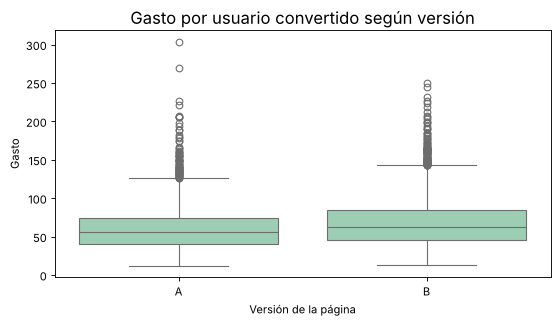

In [16]:
# Distribución del gasto por versión (usuarios convertidos)
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[df["converted"] == 1], x="landing", y="gasto", order=["A", "B"], color="#95D5B2")
plt.title("Gasto por usuario convertido según versión", fontsize=15)
plt.xlabel("Versión de la página")
plt.ylabel("Gasto")
plt.show()

### 📝 Conclusión e interpretación

**Decisión:**
Con un valor p de **≈ 3.6 × 10⁻²¹**, muy por debajo de α = 0.05, **se rechaza la hipótesis nula**. Como las varianzas no son iguales (Levene, p < 0.05), se usó la prueba t de Welch.

**Interpretación de negocio:**
Los clientes que compran en la **página B gastan en promedio 68.75**, frente a **61.09** en la página A: **7.66 más por compra (≈ 12.5 % más)**. La mediana también es mayor en B (62.57 frente a 55.84), así que la diferencia no se explica solo por unas pocas compras grandes. El estadístico t es negativo (−9.48) porque el primer grupo de la prueba, A, tiene el promedio menor. La página B genera más valor económico por cliente.

---

## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalúa si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba z para proporciones

`converted` es una variable binaria (0/1), así que lo que se compara son **proporciones** (tasas de conversión) entre dos grupos independientes. Por eso se usa la prueba z para dos proporciones. Ambos grupos tienen muchos usuarios y suficientes conversiones y no conversiones, de modo que la aproximación normal es válida.

**Hipótesis (α = 0.05):**
- **Hipótesis nula (H₀):** la tasa de conversión de la página A es igual a la de la página B.
- **Hipótesis alternativa (H₁):** la tasa de conversión de la página A es diferente a la de la página B.

In [17]:
# Número de usuarios convertidos por página
conversiones = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [18]:
# Tasa de conversión por página
tasa_A = conversiones["A"] / totales["A"]
tasa_B = conversiones["B"] / totales["B"]
print(f"Tasa de conversión página A: {tasa_A:.2%}")
print(f"Tasa de conversión página B: {tasa_B:.2%}")
print(f"Diferencia: {(tasa_B - tasa_A) * 100:.2f} puntos porcentuales "
      f"(aumento relativo de {(tasa_B - tasa_A) / tasa_A:.1%})")

Tasa de conversión página A: 12.57%
Tasa de conversión página B: 15.96%
Diferencia: 3.38 puntos porcentuales (aumento relativo de 26.9%)


In [19]:
# Aplicar prueba (orden: A, B)
exitos = [conversiones["A"], conversiones["B"]]
observaciones = [totales["A"], totales["B"]]
z_stat, p_value_z = proportions_ztest(exitos, observaciones)

# Visualizar resultados
print(f"Estadístico z: {z_stat:.3f}")
print(f"Valor p: {p_value_z:.2e}")

# Interpretar resultados
if p_value_z < alpha:
    print("\nRechazamos la hipótesis nula: hay evidencia de una diferencia en la tasa de conversión.")
    mayor = "A" if tasa_A > tasa_B else "B"
    print(f"La página {mayor} convierte más ({abs(tasa_A - tasa_B) * 100:.2f} puntos porcentuales de diferencia).")
else:
    print("\nNo rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia en la tasa de conversión.")

Estadístico z: -9.677
Valor p: 3.76e-22

Rechazamos la hipótesis nula: hay evidencia de una diferencia en la tasa de conversión.
La página B convierte más (3.38 puntos porcentuales de diferencia).


In [20]:
# Ingreso por visitante: combina conversión y gasto
ingreso_por_visitante = df.groupby("landing")["gasto"].mean()
print("Ingreso promedio por visitante:")
print(ingreso_por_visitante.round(2))
print(f"\nAumento de B frente a A: {ingreso_por_visitante['B'] / ingreso_por_visitante['A'] - 1:.1%}")

Ingreso promedio por visitante:
landing
A     7.68
B    10.97
Name: gasto, dtype: float64

Aumento de B frente a A: 42.8%


### 📝 Conclusión e interpretación

**Decisión:**
Con un valor p de **≈ 3.8 × 10⁻²²**, muy por debajo de α = 0.05, **se rechaza la hipótesis nula**.

**Interpretación de negocio:**
La **página B convierte al 15.96 %** de sus visitantes, frente al **12.57 %** de la página A: **3.38 puntos porcentuales más**, un aumento relativo de **≈ 27 %**. El estadístico z es negativo (−9.68) porque el primer grupo de la prueba, A, tiene la tasa menor.

Al combinar conversión y gasto, el **ingreso promedio por visitante** pasa de **7.68 en A a 10.97 en B (≈ 43 % más)**. La página B es más efectiva tanto para convertir visitantes como para generar ingresos.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba chi-cuadrada de independencia

Se evalúa si dos variables **categóricas** (`traffic_source` y `converted`) están relacionadas, así que se usa la prueba chi-cuadrada de independencia. Supuesto: las frecuencias esperadas deben ser al menos 5 en todas las celdas (se verifica en el código).

**Hipótesis (α = 0.05):**
- **Hipótesis nula (H₀):** la conversión es independiente de la fuente de tráfico.
- **Hipótesis alternativa (H₁):** la conversión está asociada con la fuente de tráfico.

In [21]:
# Tabla de contingencia (conteos)
tabla_traffic = pd.crosstab(df["traffic_source"], df["converted"])
print(tabla_traffic)

# Tabla normalizada (% por fuente de tráfico)
tabla_traffic_norm = pd.crosstab(df["traffic_source"], df["converted"], normalize="index") * 100
print("\n", tabla_traffic_norm.round(2))

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

 converted           0      1
traffic_source              
Ads             85.26  14.74
Email           85.01  14.99
Organic         86.21  13.79
Referral        86.12  13.88


In [22]:
# Aplicar prueba
chi2_traffic, p_value_traffic, dof_traffic, expected_traffic = chi2_contingency(tabla_traffic)
print(f"Estadístico chi-cuadrado: {chi2_traffic:.3f}")
print(f"Valor p: {p_value_traffic:.4f}")
print(f"Grados de libertad: {dof_traffic}")
print("Supuesto (frecuencias esperadas >= 5):", (expected_traffic >= 5).all())

Estadístico chi-cuadrado: 8.662
Valor p: 0.0341
Grados de libertad: 3
Supuesto (frecuencias esperadas >= 5): True


In [23]:
# Interpretar resultados
if p_value_traffic < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre la fuente de tráfico y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre la fuente de tráfico y la conversión.")

print("\nTasa de conversión por fuente (%, de mayor a menor):")
print(tabla_traffic_norm[1].sort_values(ascending=False).round(2))

Rechazamos la hipótesis nula: hay evidencia de asociación entre la fuente de tráfico y la conversión.

Tasa de conversión por fuente (%, de mayor a menor):
traffic_source
Email       14.99
Ads         14.74
Referral    13.88
Organic     13.79
Name: 1, dtype: float64


**Comparaciones por pares**

La prueba chi-cuadrada global indica que existe asociación, pero no dice **qué canales** difieren entre sí. Para comprobarlo se comparan los canales de dos en dos, aplicando la **corrección de Bonferroni** (se multiplica cada valor p por el número de comparaciones, 6) para controlar el riesgo de falsos positivos al hacer varias pruebas.

In [24]:
# Comparaciones por pares con corrección de Bonferroni
canales = sorted(df["traffic_source"].unique())
pares = list(combinations(canales, 2))
resultados = []
for c1, c2 in pares:
    sub = df[df["traffic_source"].isin([c1, c2])]
    p = chi2_contingency(pd.crosstab(sub["traffic_source"], sub["converted"]))[1]
    resultados.append({"par": f"{c1} vs {c2}", "p_valor": round(p, 4),
                       "p_bonferroni": round(min(p * len(pares), 1), 4)})

comparaciones = pd.DataFrame(resultados)
comparaciones["significativo"] = comparaciones["p_bonferroni"] < alpha
print(comparaciones.to_string(index=False))

                par  p_valor  p_bonferroni  significativo
       Ads vs Email   0.6647        1.0000          False
     Ads vs Organic   0.0219        0.1315          False
    Ads vs Referral   0.1937        1.0000          False
   Email vs Organic   0.0204        0.1223          False
  Email vs Referral   0.1295        0.7771          False
Organic vs Referral   0.8975        1.0000          False


### 📝 Conclusión e interpretación

**Decisión:**
Con un valor p de **0.034**, menor que α = 0.05, **se rechaza la hipótesis nula**: hay evidencia de asociación entre la fuente de tráfico y la conversión. Se cumple el supuesto de frecuencias esperadas ≥ 5.

**Interpretación de negocio:**
- **En cantidades absolutas**, **Organic** aporta más conversiones (2,480), seguido de **Ads** (1,759), porque son los canales con más usuarios. **Referral** es el que menos aporta (549).
- **En tasa de conversión**, **Email (14.99 %)** y **Ads (14.74 %)** muestran tasas ligeramente más altas que **Referral (13.88 %)** y **Organic (13.79 %)**.
- El efecto es **pequeño**: 1.2 puntos porcentuales entre la tasa más alta y la más baja, con un valor p cercano al umbral. Además, en las comparaciones por pares **ninguna diferencia individual es significativa tras la corrección de Bonferroni**. La evidencia apunta a una asociación global débil, no a que un canal específico sea claramente mejor que otro.
- Una posible explicación es que los usuarios de Email y Ads lleguen con mayor intención de compra, pero el dataset no mide la intención, así que es una hipótesis por validar.

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba chi-cuadrada de independencia

Se evalúa si dos variables **categóricas** (`user_type` y `converted`) están relacionadas, así que se usa la prueba chi-cuadrada de independencia. Supuesto: las frecuencias esperadas deben ser al menos 5 en todas las celdas.

**Hipótesis (α = 0.05):**
- **Hipótesis nula (H₀):** la conversión es independiente del tipo de usuario (nuevo o recurrente).
- **Hipótesis alternativa (H₁):** la conversión está asociada con el tipo de usuario.

In [25]:
# Tabla de contingencia (conteos)
tabla_user = pd.crosstab(df["user_type"], df["converted"])
print(tabla_user)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [26]:
# Tabla normalizada (% por tipo de usuario)
tabla_user_norm = pd.crosstab(df["user_type"], df["converted"], normalize="index") * 100
print(tabla_user_norm.round(2))

converted       0      1
user_type               
Nuevo       85.64  14.36
Recurrente  85.91  14.09


In [27]:
# Aplicar prueba
chi2_user, p_value_user, dof_user, expected_user = chi2_contingency(tabla_user)
print(f"Estadístico chi-cuadrado: {chi2_user:.3f}")
print(f"Valor p: {p_value_user:.4f}")
print(f"Grados de libertad: {dof_user}")
print("Supuesto (frecuencias esperadas >= 5):", (expected_user >= 5).all())

# Interpretar resultados
if p_value_user < alpha:
    print("\nRechazamos la hipótesis nula: hay evidencia de asociación entre el tipo de usuario y la conversión.")
else:
    print("\nNo rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.")

Estadístico chi-cuadrado: 0.513
Valor p: 0.4736
Grados de libertad: 1
Supuesto (frecuencias esperadas >= 5): True

No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**
Con un valor p de **0.474**, mayor que α = 0.05, **no se rechaza la hipótesis nula**.

**Interpretación de negocio:**
Los usuarios **nuevos convierten al 14.36 %** y los **recurrentes al 14.09 %**, una diferencia de solo 0.27 puntos porcentuales. **No se observa evidencia de que el tipo de usuario se asocie con la conversión**. Esto no demuestra que no exista ninguna diferencia, pero, con los datos disponibles, no hay base para diseñar una estrategia de conversión distinta para nuevos y recurrentes.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

In [28]:
# Orden de canales por tasa de conversión (se usa en ambos gráficos)
orden_canales = tabla_traffic_norm[1].sort_values(ascending=False).index.tolist()
print(tabla_traffic.loc[orden_canales])

converted           0     1
traffic_source             
Email            5205   918
Ads             10176  1759
Referral         3406   549
Organic         15507  2480


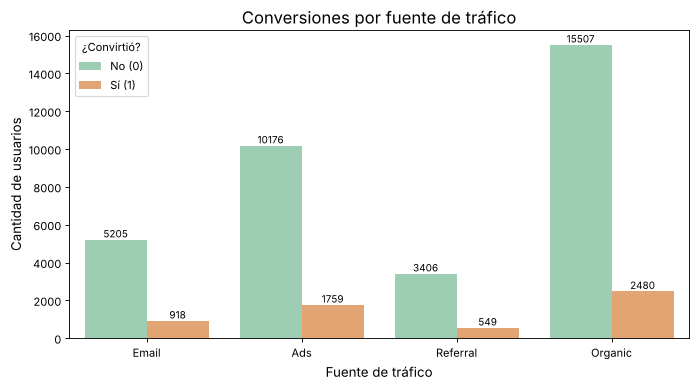

In [29]:
# Gráfico de barras agrupadas (conteos)
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x="traffic_source", hue="converted", order=orden_canales,
                   palette=["#95D5B2", "#F4A261"])
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", fontsize=9)
plt.title("Conversiones por fuente de tráfico", fontsize=15)
plt.xlabel("Fuente de tráfico", fontsize=12)
plt.ylabel("Cantidad de usuarios", fontsize=12)
plt.legend(title="¿Convirtió?", labels=["No (0)", "Sí (1)"])
plt.show()

📌 **Lectura del gráfico**

El gráfico muestra la **cantidad absoluta** de usuarios que convirtieron y no convirtieron en cada canal. **Organic** es, por mucho, el canal con más usuarios (17,987) y más conversiones (2,480), seguido de **Ads**; **Referral** es el más pequeño. El volumen depende sobre todo de cuántos usuarios trae cada canal, así que este gráfico no basta para saber cuál es más efectivo.

In [30]:
# Proporciones de conversión por fuente de tráfico (mismo orden)
print(tabla_traffic_norm.loc[orden_canales].round(2))

converted           0      1
traffic_source              
Email           85.01  14.99
Ads             85.26  14.74
Referral        86.12  13.88
Organic         86.21  13.79


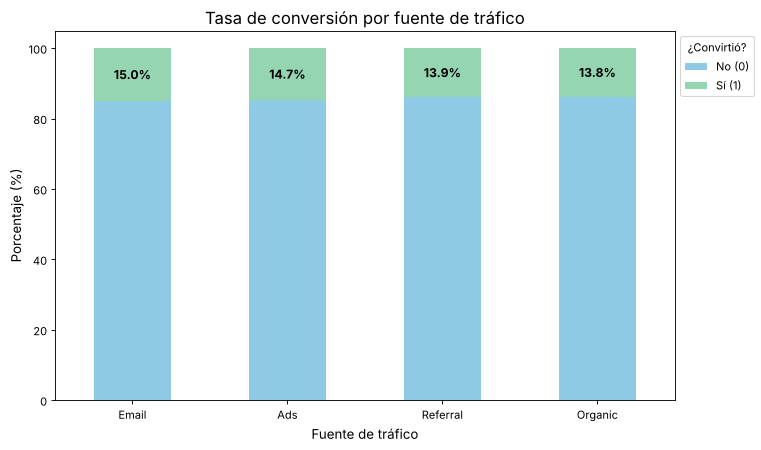

In [31]:
# Gráfico de barras apiladas (proporciones)
ax = tabla_traffic_norm.loc[orden_canales].plot(kind="bar", stacked=True, figsize=(10, 6),
                                                 color=["#8ecae6", "#95d5b2"])
ax.bar_label(ax.containers[1], fmt="%.1f%%", label_type="center", fontsize=11, fontweight="bold")
plt.title("Tasa de conversión por fuente de tráfico", fontsize=15)
plt.ylabel("Porcentaje (%)", fontsize=12)
plt.xlabel("Fuente de tráfico", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="¿Convirtió?", labels=["No (0)", "Sí (1)"], loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

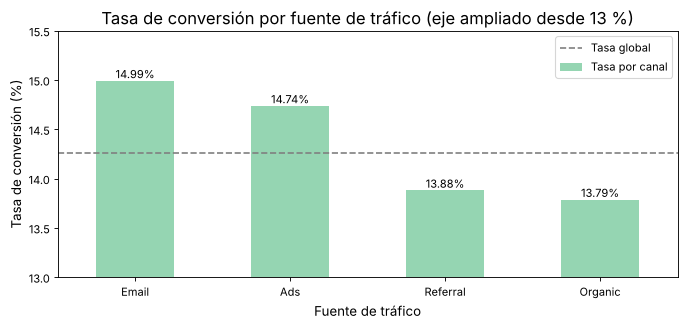

In [32]:
# Zoom en la tasa de conversión (eje ampliado para ver diferencias pequeñas)
tasas_canal = tabla_traffic_norm.loc[orden_canales, 1]
plt.figure(figsize=(10, 4))
ax = tasas_canal.plot(kind="bar", color="#95d5b2", label="Tasa por canal")
ax.bar_label(ax.containers[0], fmt="%.2f%%", fontsize=10)
plt.axhline(df["converted"].mean() * 100, color="gray", linestyle="--", label="Tasa global")
plt.ylim(13, 15.5)
plt.title("Tasa de conversión por fuente de tráfico (eje ampliado desde 13 %)", fontsize=15)
plt.ylabel("Tasa de conversión (%)", fontsize=12)
plt.xlabel("Fuente de tráfico", fontsize=12)
plt.xticks(rotation=0)
plt.legend()
plt.show()

📌 **Lectura del gráfico**

El gráfico apilado muestra la **proporción** de usuarios que convirtieron dentro de cada canal (cada barra suma 100 %), así que compara la efectividad sin que influya el volumen. Como la parte que no convierte ocupa cerca del 85 % de cada barra, el gráfico de zoom amplía el eje para que se vean las diferencias: **Email (14.99 %)** y **Ads (14.74 %)** quedan por encima de la tasa global y **Referral (13.88 %)** y **Organic (13.79 %)** por debajo. Las diferencias son de apenas 1.2 puntos porcentuales, lo que es coherente con una asociación global débil.

### Relación entre el tipo de usuario y la conversión

In [33]:
# Conteos de conversión por tipo de usuario
print(tabla_user)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


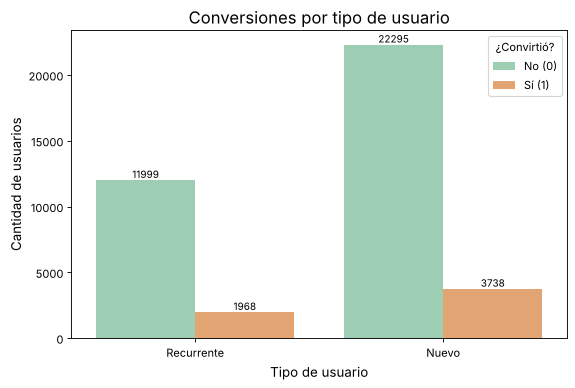

In [34]:
# Gráfico de barras agrupadas (conteos)
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="user_type", hue="converted", palette=["#95D5B2", "#F4A261"])
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", fontsize=9)
plt.title("Conversiones por tipo de usuario", fontsize=15)
plt.xlabel("Tipo de usuario", fontsize=12)
plt.ylabel("Cantidad de usuarios", fontsize=12)
plt.legend(title="¿Convirtió?", labels=["No (0)", "Sí (1)"])
plt.show()

📌 **Lectura del gráfico**

El gráfico muestra la **cantidad absoluta** de usuarios nuevos y recurrentes que convirtieron y no convirtieron. Hay casi el doble de usuarios **nuevos** (26,033) que recurrentes (13,967), por eso los nuevos aportan más conversiones en volumen (3,738 frente a 1,968). Para comparar su efectividad hay que mirar las proporciones del siguiente gráfico.

In [35]:
# Proporciones de conversión por tipo de usuario
print(tabla_user_norm.round(2))

converted       0      1
user_type               
Nuevo       85.64  14.36
Recurrente  85.91  14.09


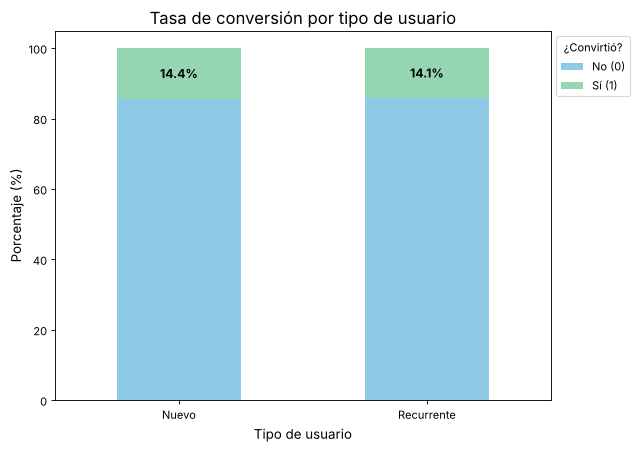

In [36]:
# Gráfico de barras apiladas (proporciones)
ax = tabla_user_norm.plot(kind="bar", stacked=True, figsize=(8, 6), color=["#8ecae6", "#95d5b2"])
ax.bar_label(ax.containers[1], fmt="%.1f%%", label_type="center", fontsize=11, fontweight="bold")
plt.title("Tasa de conversión por tipo de usuario", fontsize=15)
plt.ylabel("Porcentaje (%)", fontsize=12)
plt.xlabel("Tipo de usuario", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="¿Convirtió?", labels=["No (0)", "Sí (1)"], loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

📌 **Lectura del gráfico**

En proporciones, los usuarios **nuevos convierten al 14.36 %** y los **recurrentes al 14.09 %**. Las dos barras son prácticamente iguales, lo que coincide con la prueba chi-cuadrada (p = 0.474): no se observa evidencia de que el tipo de usuario se asocie con la conversión.

## 🧩 Paso 7: Insight ejecutivo para stakeholders

Se traducen los hallazgos del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**
- ¿Qué página genera mayor conversión y gasto promedio?
- ¿Qué canales de tráfico son más efectivos para generar conversiones?
- ¿Existen diferencias significativas según el tipo de usuario?
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?

---

### 🌟 Insight ejecutivo basado en el experimento A/B

#### 🔍 **Comparación de página (A vs B)**

**Gasto promedio por usuario que convirtió:**
- Página A: **61.09** en promedio (mediana 55.84); página B: **68.75** (mediana 62.57), **+7.66 por compra (≈ 12.5 % más)**.
- Prueba t de Welch: valor p ≈ 3.6 × 10⁻²¹ → se rechaza H₀.
- **Interpretación:** los clientes de la página B gastan significativamente más por compra.

<br>

**Tasa de conversión:**
- Página A: **12.57 %**; página B: **15.96 %** (**+3.38 puntos porcentuales, ≈ 27 % más**).
- Prueba z: valor p ≈ 3.8 × 10⁻²² → se rechaza H₀.
- **Interpretación:** la página B convierte significativamente más visitantes en clientes. Al combinar conversión y gasto, el **ingreso promedio por visitante** pasa de **7.68 en A a 10.97 en B (≈ 43 % más)**.

---

#### 📊 **Segmentación por fuente de tráfico**
- Chi-cuadrada: valor p = **0.034** → hay asociación global. **Email (14.99 %)** y **Ads (14.74 %)** muestran tasas ligeramente más altas que **Referral (13.88 %)** y **Organic (13.79 %)**; Organic es el canal con más volumen.
- **Interpretación:** el efecto del canal es pequeño (1.2 puntos porcentuales) y ninguna diferencia por pares resulta significativa tras la corrección de Bonferroni. No hay evidencia sólida de que un canal específico convierta mejor que otro.

---

#### 📊 **Segmentación por tipo de usuario**
- Chi-cuadrada: valor p = **0.474** → no se rechaza H₀. Nuevos: **14.36 %**; recurrentes: **14.09 %**.
- **Interpretación:** no se observa evidencia de que el tipo de usuario se asocie con la conversión.

---

#### 📈 **Qué muestran las visualizaciones**
- En los gráficos de conteos, **Organic** y los **usuarios nuevos** dominan en volumen porque son los grupos más grandes.
- En los gráficos de proporciones, las tasas de los canales están muy cerca entre sí (13.8 %–15.0 %) y las barras de **nuevos y recurrentes son casi idénticas**, en línea con los resultados de las pruebas.

---

#### 💡 **Recomendaciones de negocio**
- **Implementar la página B**: mejora las dos métricas principales, con más conversión y más gasto por cliente, y aumenta el ingreso por visitante en ≈ 43 %.
- **Aprovechar el volumen de Organic** con la nueva página, ya que es el canal que más usuarios trae. Las diferencias de conversión entre canales son pequeñas, así que la asignación de presupuesto debería basarse también en el **costo de adquisición** de cada canal.
- **Validar con un experimento dirigido** si Email y Ads realmente convierten mejor antes de reasignar presupuesto hacia ellos.
- **No segmentar la landing por tipo de usuario**: con los datos actuales, una sola versión (B) sirve para nuevos y recurrentes.

#### ⚠️ **Limitaciones**
- El experimento duró 28 días (1–28 de enero de 2026); los resultados podrían cambiar en otras temporadas, como fechas de alta demanda.
- No se analizaron región ni dispositivo, que podrían tener efectos propios o interactuar con la versión de la página.
- Al hacer varias pruebas aumenta la probabilidad de algún resultado significativo por azar; esto afecta sobre todo a la prueba de canales (p = 0.034), no a las de A/B (p ≈ 0).
- Los análisis por canal y por tipo de usuario muestran asociaciones, no causalidad.